--Evaluating how model performs using diff metrics and builing first real predictive model
--simple linear regression

In [1]:
low__memory=False
import numpy as np
import matplotlib.pyplot  as plt
import pandas as pd
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

## Supervised learning
teaching a computer by showing it example
-Var in our analysis:
-Dependent variable(y)-What wr want to predict
-independent variable(x)-what we use to make the prediction
We use simple linear regression where variables are linear and continuous(can take any value in a range): temp(20.5,20.6....)
relation looks linear which flws a straight line


## problem setting
>> simple linear regression for data
like predict student test score by their study hours
like estaminate house price by the size of it
forcasting business by its own data
in all this cases we look for linear pattern...when one value goes up does the other value go up or down in a linear or consistent way

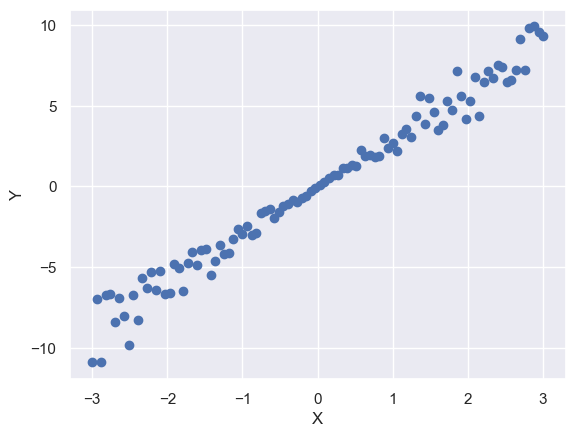

In [2]:
n_obs =100
x=np.linspace(-3,3,n_obs)
X= x[:,np.newaxis]
y = x + x*np.random.normal(2,.5,n_obs)
plt.plot(x,y,'o')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

points-
as x increases y also increases
the relationship looks fairly steady- theres a clear pattern
if we know x we can make a reasonalbe guess about y
# Linear regression formula:
                 y = β₀ + β₁x
predicting ice cream sales;;
imagine youre running an ice cream shop and want to predict daily sales based on temperature:
y= Daily ice cream sales (in euro)
x= temp (in c)
β₀(beta 0) = sales when temp is 0..example = 50(sales worth of ice cream at 0 degree)
β₁(beta 1) =  sales increase per degree(how much sales go up when temp rises)...example = 10(sales increase by 10 for each degree increase)
then at 25 degree it will be 
y=50+10*25
y=300

Model estimation
Ordinary least squares algorithm

In [3]:
regressor = LinearRegression()
regressor.fit(X,y) #fitted very first model

LinearRegression()

In [4]:
print("Intercept (beta 0): {}".format(regressor.intercept_)) # intercept is beta 0
print("Slope (beta 1): {}".format(regressor.coef_[0])) # slope is beta 1

Intercept (beta 0): -0.0107946052883973
Slope (beta 1): 2.9587775629096513


In [5]:
regressor.coef_[0] * (-2) + regressor.intercept_

np.float64(-5.9283497311077)

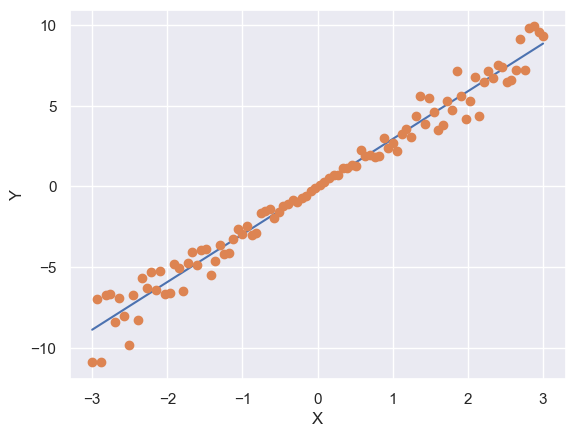

In [6]:
#graphical representation
min_pt = X.min()*regressor.coef_[0]+regressor.intercept_
max_pt = X.max()*regressor.coef_[0]+regressor.intercept_
plt.plot([X.min(),X.max()],[min_pt,max_pt])
plt.plot(X,y,'o')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

# Model evaluation
Based on the graph its very clear that the model is good. 
there are two main criteria for regression evaluation: the r^2 score and the MSE
# Variational measure(r^2)
think of it as a grade for model performance,But on a scale from 0-100%
what is tells us
0%=the model is just guessing
50%=the model is doing okay,but missing half a story
90%= the model is doing great
100%=perfect prediction
a higher variation measure means the model is making good prediction but even a lower one can be usefull

In [7]:
print('The r2 score of hte model on the test set is:', regressor.score(X,y))

The r2 score of hte model on the test set is: 0.9745928612335101


# MAE(mean absolute error)
MAE is like measuring the avg size of our prediction mistakes.The avg size of model errors
formula = (actual1-pred1)+(actual2-pred2)+...(actualn-predn)/n
the smaller the MAE the stronger the prediction model

In [8]:
y_pred=regressor.predict(X).reshape(-1,1)
print("the mae of the model on the test set is:",mean_absolute_error(y_pred,y))

the mae of the model on the test set is: 0.6176874482170016


# MSE(mean squared error)
MSE is like MAEs stricter cousin...its tougher on big mistakes
the formula-(actual1-pred1)^2+(actual2-pred2)^2+...(actualn-predn)^2/n
Lower mse better model

# diff
the mae says how many errors my model is wrong by
the mse says how large my errors with big errors causing

In [9]:
print("The mse of the model on the test set is:",mean_squared_error(y_pred,y))

The mse of the model on the test set is: 0.698497089698961
